# ER Wait Time & Patient Flow Analysis

**Business problem:** Where do patients wait longest in the emergency room, and what does it cost the hospital in patient safety and capacity?

**Data:** 10,200+ synthetic ER visits (Jan 2025 - Aug 2026), one row per visit. No real patient data.

**Tools:** Python, pandas, matplotlib

**Questions answered:**
1. How does wait time change with patient acuity (ESI level)?
2. Do time of day and season affect waits?
3. What share of patients leave without being seen (LWBS), and is it linked to long waits?
4. How long do admitted patients board while waiting for a bed?
5. How long does each type of patient stay in the ER overall?

In [39]:
import pandas as pd

df = pd.read_csv("er_visits_raw.csv")

datetime_cols = ["arrival_datetime", "triage_datetime", "provider_datetime", 
                  "disposition_datetime", "departure_datetime"]
df[datetime_cols] = df[datetime_cols].apply(pd.to_datetime)

df.head()

,visit_id,arrival_datetime,triage_datetime,provider_datetime,disposition_datetime,departure_datetime,esi_level,chief_complaint,arrival_mode,age,gender,disposition,door_to_provider_min,boarding_min,total_los_min
0,100015,2025-01-01 03:08:00,2025-01-01 03:19:43.577523,2025-01-01 04:14:22.912262,2025-01-01 04:41:17.167027,2025-01-01 05:05:44.810348,3,Sprain,Ambulance,23,M,Discharged,66.4,0.0,117.7
1,100016,2025-01-01 04:19:00,2025-01-01 04:27:38.397987,2025-01-01 05:15:04.252816,2025-01-01 05:59:27.511818,2025-01-01 06:15:20.955479,3,Dizziness,Walk-in,13,F,Discharged,56.1,0.0,116.3
2,100024,2025-01-01 08:08:00,2025-01-01 08:13:46.721467,2025-01-01 08:30:43.095025,2025-01-01 09:17:45.202715,2025-01-01 12:22:32.241592,2,Chest Pain,Walk-in,36,M,Admitted,22.7,184.8,254.5
3,100014,2025-01-01 08:16:00,2025-01-01 08:25:07.364824,2025-01-01 09:50:41.901899,2025-01-01 10:20:42.747181,2025-01-01 11:34:04.050842,3,Flu-like Symptoms,Walk-in,5,M,Admitted,94.7,73.4,198.1
4,100008,2025-01-01 08:17:00,2025-01-01 08:23:07.343438,2025-01-01 08:36:35.116342,2025-01-01 09:29:53.578473,2025-01-01 09:48:54.487182,2,Flu-like Symptoms,Ambulance,33,M,Discharged,19.6,0.0,91.9


In [40]:
df.dtypes

visit_id                         int64
arrival_datetime        datetime64[us]
triage_datetime         datetime64[us]
provider_datetime       datetime64[us]
disposition_datetime    datetime64[us]
departure_datetime      datetime64[us]
esi_level                        int64
chief_complaint                    str
arrival_mode                       str
age                              int64
gender                             str
disposition                        str
door_to_provider_min           float64
boarding_min                   float64
total_los_min                  float64
dtype: object

In [41]:
# Data-quality checks: confirm the file is clean before trusting the analysis

# 1. Size of the dataset: (rows, columns)
print("Shape:", df.shape)

# 2. Missing values per column
print("\nMissing values:\n", df.isna().sum())

# 3. Fully duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Duplicate visit IDs (each visit should appear once)
print("Duplicate visit_ids:", df["visit_id"].duplicated().sum())

# 5. Min/max of key numeric columns, to catch impossible values
df[["age", "door_to_provider_min", "total_los_min"]].describe()

Shape: (10213, 15)

Missing values:
 visit_id                   0
arrival_datetime           0
triage_datetime            0
provider_datetime          0
disposition_datetime    1157
departure_datetime         0
esi_level                  0
chief_complaint            0
arrival_mode               0
age                        0
gender                     0
disposition                0
door_to_provider_min       0
boarding_min            1157
total_los_min              0
dtype: int64

Duplicate rows: 0
Duplicate visit_ids: 0


,age,door_to_provider_min,total_los_min
count,10213.000000,10213.000000,10213.000000
mean,41.678449,77.138422,148.046020
std,21.150770,58.184830,70.276535
min,0.000000,2.000000,6.800000
25%,27.000000,32.800000,99.800000
50%,41.000000,63.200000,134.100000
75%,56.000000,107.000000,182.800000
max,134.000000,448.100000,555.900000


In [42]:
df.groupby("disposition")["total_los_min"].mean()

disposition
Admitted      200.613120
Discharged    138.867068
LWBS          126.337943
Name: total_los_min, dtype: float64

In [43]:
# Extract hour and month from arrival time for wait-time analysis by time of day/season
df["arrival_hour"] = df["arrival_datetime"].dt.hour
df["arrival_month"] = df["arrival_datetime"].dt.month

# Flag winter visits (Dec, Jan, Feb) to compare against rest of year
df["is_winter"] = df["arrival_month"].isin([12, 1, 2])

# Confirm the new columns look correct
df[["arrival_datetime", "arrival_hour", "arrival_month", "is_winter"]].head()

,arrival_datetime,arrival_hour,arrival_month,is_winter
0,2025-01-01 03:08:00,3,1,True
1,2025-01-01 04:19:00,4,1,True
2,2025-01-01 08:08:00,8,1,True
3,2025-01-01 08:16:00,8,1,True
4,2025-01-01 08:17:00,8,1,True


In [44]:
# Business question: does wait time vary by patient acuity (ESI level)?
# Groups all visits by esi_level, averages door_to_provider_min within each group
df.groupby("esi_level")["door_to_provider_min"].mean()

esi_level
1      6.114352
2     19.155731
3     57.262597
4    114.945618
5    162.229552
Name: door_to_provider_min, dtype: float64

In [45]:
# Business question: what % of patients leave without being seen, and is it tied to long waits?
lwbs_rate = (df["disposition"] == "LWBS").mean()
print(f"Overall LWBS rate: {lwbs_rate:.1%}")

# Compare average wait time for low-acuity (ESI 4/5) patients who left vs who stayed
low_acuity = df[df["esi_level"].isin([4, 5])]
low_acuity.groupby("disposition")["door_to_provider_min"].mean()

Overall LWBS rate: 11.3%


disposition
Admitted      111.489231
Discharged    122.421885
LWBS          144.661895
Name: door_to_provider_min, dtype: float64

In [46]:
# Business question: how long do admitted patients wait for an inpatient bed, and is it worse in winter?
admitted = df[df["disposition"] == "Admitted"]
admitted.groupby("is_winter")["boarding_min"].mean()

is_winter
False     90.524958
True     179.444870
Name: boarding_min, dtype: float64

In [47]:
# Business question: does time of day or season affect how long patients wait?
# Average wait by arrival hour (0-23) to find peak-congestion hours
print(df.groupby("arrival_hour")["door_to_provider_min"].mean())

# Average wait in winter vs rest of year
df.groupby("is_winter")["door_to_provider_min"].mean()

arrival_hour
0     63.370225
1     75.476471
2     57.671429
3     64.726966
4     65.867089
5     68.062011
6     69.068679
7     66.742432
8     65.173016
9     66.609713
10    66.293119
11    67.577358
12    67.134110
13    67.376322
14    70.088608
15    65.930303
16    63.122957
17    66.973004
18    94.756582
19    93.657995
20    89.208170
21    92.483743
22    96.895247
23    90.805307
Name: door_to_provider_min, dtype: float64


is_winter
False    70.568620
True     91.093974
Name: door_to_provider_min, dtype: float64

In [48]:
# Install matplotlib (plotting library) into this notebook's Python environment
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [49]:
# Import the plotting module; "plt" is the standard short name
import matplotlib.pyplot as plt

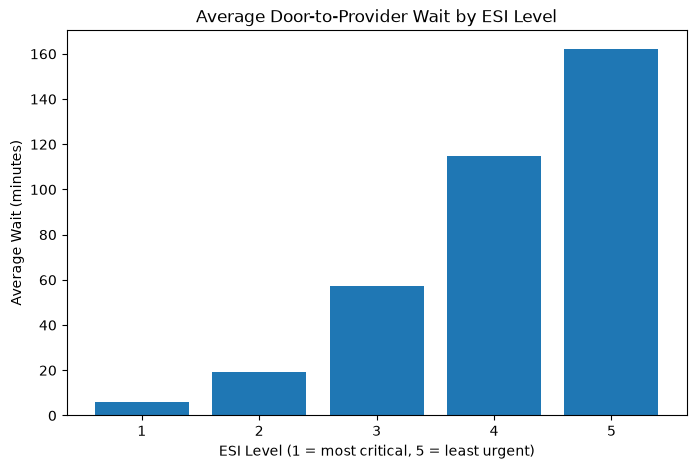

In [50]:
# Business question: how much longer do lower-acuity patients wait? (chart of the ESI finding)
wait_by_esi = df.groupby("esi_level")["door_to_provider_min"].mean()

# Draw a bar chart: one bar per ESI level
plt.figure(figsize=(8, 5))
plt.bar(wait_by_esi.index, wait_by_esi.values)

# Label the chart so it reads on its own
plt.title("Average Door-to-Provider Wait by ESI Level")
plt.xlabel("ESI Level (1 = most critical, 5 = least urgent)")
plt.ylabel("Average Wait (minutes)")
plt.show()

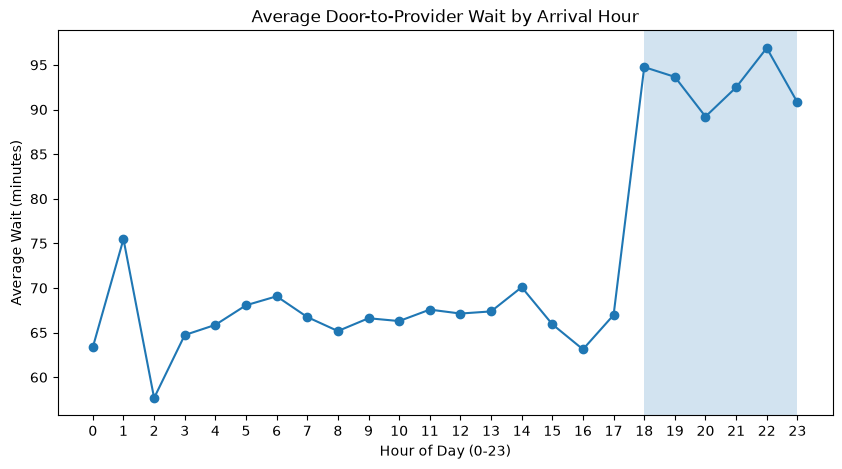

In [51]:
# Business question: when during the day are waits longest? (chart of the hour-of-day finding)
wait_by_hour = df.groupby("arrival_hour")["door_to_provider_min"].mean()

# Line chart: one point per hour, connected to show the trend across the day
plt.figure(figsize=(10, 5))
plt.plot(wait_by_hour.index, wait_by_hour.values, marker="o")

# Shade the evening window (6pm-11pm) where waits jump
plt.axvspan(18, 23, alpha=0.2)

plt.title("Average Door-to-Provider Wait by Arrival Hour")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Average Wait (minutes)")
plt.xticks(range(0, 24))
plt.show()

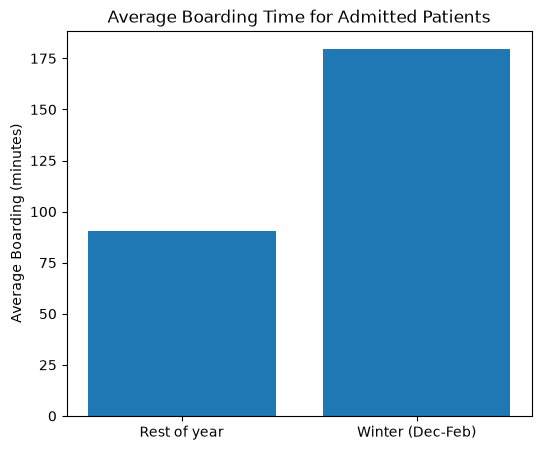

In [52]:
# Business question: how much does winter add to the wait for an inpatient bed? (chart of the boarding finding)
admitted = df[df["disposition"] == "Admitted"]
boarding_by_season = admitted.groupby("is_winter")["boarding_min"].mean()

# Bar chart with two bars; rename the True/False index so the labels read clearly
plt.figure(figsize=(6, 5))
plt.bar(["Rest of year", "Winter (Dec-Feb)"], boarding_by_season.values)

plt.title("Average Boarding Time for Admitted Patients")
plt.ylabel("Average Boarding (minutes)")
plt.show()

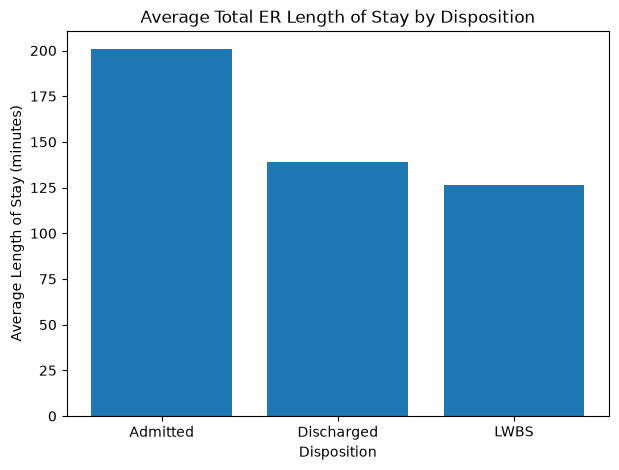

In [53]:
# Business question: which patients spend the longest total time in the ER? (chart of the length-of-stay finding)
los_by_disposition = df.groupby("disposition")["total_los_min"].mean()

# Sort so the bars run from longest to shortest stay
los_by_disposition = los_by_disposition.sort_values(ascending=False)

plt.figure(figsize=(7, 5))
plt.bar(los_by_disposition.index, los_by_disposition.values)

plt.title("Average Total ER Length of Stay by Disposition")
plt.xlabel("Disposition")
plt.ylabel("Average Length of Stay (minutes)")
plt.show()

## Key Findings

1. **Wait time rises sharply as acuity drops.** Average door-to-provider wait grows from about 6 minutes (ESI 1) to about 162 minutes (ESI 5), consistent with triage working as intended.
2. **Evening and winter are the pressure points.** Waits are about 40% longer from 6pm to 11pm and about 29% longer in winter (Dec-Feb).
3. **Long waits drive patients away.** 11.3% of visits ended in LWBS (left without being seen). Among low-acuity patients (ESI 4-5), those who left had waited about 145 minutes, compared with about 122 minutes for those who were discharged.
4. **Boarding nearly doubles in winter.** Admitted patients waited about 90 minutes for an inpatient bed outside winter and about 179 minutes in winter, which points to hospital bed capacity rather than ER staffing.
5. **Admitted patients stay longest.** Average total ER stay is about 200 minutes for admitted patients versus about 139 minutes for discharged patients, driven by boarding time.

## Recommendations

- Add ER staffing during the 6pm-11pm window.
- Plan winter surge capacity for inpatient beds to reduce boarding.
- Track the LWBS rate among ESI 4-5 patients as a patient-safety metric.

## Data Notes and Limitations

- Data-quality checks (missing values, duplicates, value ranges) found no problems. The only blanks are expected: LWBS patients have no disposition time or boarding time.
- The data is synthetic, so findings illustrate method rather than real hospital performance.
- The cause of the winter increase cannot be confirmed without additional data, such as inpatient bed occupancy.